# Week 4 — Temperature: PhysioNet (FDA face/oral temperature) + MCD-rPPG

**Goal.** Follow the supervisor's plan: set up the PhysioNet facial/oral temperature dataset first, then add MCD-rPPG data in training, and test whether rPPG/heart-rate information adds anything on top.

**What each dataset can contribute**

| | PhysioNet `face-oral-temp-data` | MCD-rPPG |
|---|---|---|
| Subjects | ~1,020 (FLIR) / ~1,009 (ICI) | 600 × 2 sessions |
| Label | oral temperature (monitor mode), ~11 % > 37.5 °C | non-contact thermometer, near-constant (std ≈ 0.13 °C) |
| Camera signal | 26 facial temperatures from thermal images (CSV only) | RGB video → rPPG |
| Shared with the other | age (binned), sex | age, sex |

PhysioNet has **no video and no pixels**, so rPPG cannot be extracted from it. The two datasets share only age, sex and the temperature label. That determines the design:

| Phase | What | Trains on | Evaluated on |
|---|---|---|---|
| 1 | Load + profile PhysioNet | — | — |
| 2 | PhysioNet baselines + **thermal ceiling** | PhysioNet train | PhysioNet test (MAE, fever AUC) |
| 3 | Load MCD, harmonise, **pooled demographic prior** (4 strategies) | PhysioNet train + MCD train | MCD test, PhysioNet test |
| 4 | **rPPG / HR residual model** on top of the prior | MCD train | MCD test |
| 5 | Physiology check: how much temperature signal can HR carry in MCD? | — | — |
| 6 | Results table + decision gate | | |

Every model is compared with the constant baseline (train median) on the same rows, with a patient-level bootstrap 95 % interval for the skill.

## 0. Setup and configuration
Edit the paths in the next cell if your Drive layout differs. `RPPG_FEATURES_CSV` is optional: point it at your week-2 per-session rPPG feature table (columns `patient_id`, `step`, plus numeric features). If it is empty or missing, Phase 4 uses the spot `pulse` reading as an **oracle HR proxy** and labels it as such.

In [ ]:
import os, re, sys, glob, json, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, RepeatedKFold, GroupKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, roc_auc_score

warnings.filterwarnings("ignore", category=RuntimeWarning)   # nanmean of all-NaN rounds
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
try:
    display
except NameError:            # running outside Jupyter
    display = print

# ---- Google Drive (Colab) ----
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB and not os.environ.get("W4_NO_DRIVE"):
    from google.colab import drive
    drive.mount("/content/drive")

# ---- Paths (same Drive layout as weeks 1-2) ----
MCD_ROOT   = os.environ.get("W4_MCD_ROOT",   "/content/drive/MyDrive/MCD_rPPG")
MCD_DB     = os.path.join(MCD_ROOT, "db.csv")
PHYSIO_DIR = os.environ.get("W4_PHYSIO_DIR", os.path.join(MCD_ROOT, "physionet_face_oral_temp"))
OUT_DIR    = os.environ.get("W4_OUT_DIR",    os.path.join(MCD_ROOT, "week4_outputs"))
RPPG_FEATURES_CSV = os.environ.get("W4_RPPG_FEATURES", "")   # optional week-2 rPPG feature table

# ---- Settings ----
SEED      = 43        # same patient split seed as week 2 / MCD-rPPG-baselines
FEVER_C   = 37.5      # PhysioNet fever threshold (oral)
N_BOOT    = 2000      # bootstrap resamples for 95 % intervals
CAMERA    = "FullHDwebcam"   # MCD camera used for rPPG features (labels are identical across cameras)

os.makedirs(PHYSIO_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)
RESULTS = []          # every evaluation appends a row here; saved at the end
print("MCD db:", MCD_DB, "| exists:", os.path.exists(MCD_DB))
print("PhysioNet dir:", PHYSIO_DIR)
print("Outputs:", OUT_DIR)

Mounted at /content/drive
MCD db: /content/drive/MyDrive/MCD_rPPG/db.csv | exists: True
PhysioNet dir: /content/drive/MyDrive/MCD_rPPG/physionet_face_oral_temp
Outputs: /content/drive/MyDrive/MCD_rPPG/week4_outputs


### Shared helpers
Models (Ridge, RandomForest, HistGBR with MAE loss, as in week 2), a patient-level bootstrap for skill vs the constant, and one `evaluate()` that records every result.

In [ ]:
def make_models():
    return {
        "Ridge": Pipeline([("imp", SimpleImputer(strategy="median")),
                           ("sc", StandardScaler()),
                           ("m", RidgeCV(alphas=np.logspace(-3, 3, 13)))]),
        "RF":    Pipeline([("imp", SimpleImputer(strategy="median")),
                           ("m", RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                       random_state=SEED, n_jobs=-1))]),
        "HGB":   HistGradientBoostingRegressor(loss="absolute_error", max_iter=300,
                                               learning_rate=0.05, min_samples_leaf=20,
                                               random_state=SEED),
    }

def group_boot_skill(abs_model, abs_ref, groups, n=N_BOOT, seed=SEED):
    """Skill % = 100*(1 - MAE_model/MAE_ref), resampling whole groups (patients)."""
    abs_model, abs_ref = np.asarray(abs_model, float), np.asarray(abs_ref, float)
    _, inv = np.unique(np.asarray(groups), return_inverse=True)
    sa, sb, cnt = (np.bincount(inv, abs_model), np.bincount(inv, abs_ref),
                   np.bincount(inv).astype(float))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(cnt), size=(n, len(cnt)))
    a = sa[idx].sum(1) / cnt[idx].sum(1)
    b = sb[idx].sum(1) / cnt[idx].sum(1)
    with np.errstate(divide="ignore", invalid="ignore"):
        sk = 100 * (1 - a / b)
    sk = sk[np.isfinite(sk)]
    lo, hi = (np.percentile(sk, [2.5, 97.5]) if len(sk) else (np.nan, np.nan))
    return lo, hi

def evaluate(phase, eval_set, strategy, model, features, y_true, y_pred, y_ref, groups,
             ref_name="constant", fever_thr=None, show=True):
    y_true, y_pred, y_ref = map(lambda a: np.asarray(a, float), (y_true, y_pred, y_ref))
    am, ar = np.abs(y_true - y_pred), np.abs(y_true - y_ref)
    mae, mae_ref = am.mean(), ar.mean()
    skill = 100 * (1 - mae / mae_ref) if mae_ref > 0 else np.nan
    lo, hi = group_boot_skill(am, ar, groups)
    auc = np.nan
    if fever_thr is not None:
        lab = y_true > fever_thr
        if 0 < lab.sum() < len(lab):
            auc = roc_auc_score(lab, y_pred)
    row = dict(phase=phase, eval_set=eval_set, strategy=strategy, model=model, features=features,
               n=len(y_true), MAE=round(mae, 4), ref=ref_name, ref_MAE=round(mae_ref, 4),
               skill_pct=round(skill, 2), skill_lo=round(lo, 2), skill_hi=round(hi, 2),
               fever_AUC=round(auc, 3) if np.isfinite(auc) else np.nan)
    RESULTS.append(row)
    if show:
        auc_s = f" | fever AUC {auc:.3f}" if np.isfinite(auc) else ""
        print(f"[{phase}] {eval_set:<10} {strategy:<24} {model:<6} {features:<22} "
              f"MAE {mae:.4f} vs {ref_name} {mae_ref:.4f} -> skill {skill:+6.2f}% "
              f"[{lo:+.2f}, {hi:+.2f}]{auc_s}")
    return row

## Phase 1 — PhysioNet: download, load, profile
Files: `FLIR_groups1and2.csv` (main, IRT-1) and `ICI_groups1and2.csv` (second camera, robustness). CC0 licence, 2.4 MB total.

**Format notes (checked against the real file):**
- 3 header rows; the third row holds the column names.
- Each subject has 4 measurement rounds × 27 thermal columns, separated by blank columns.
- Round 4 has a typo (`T_LC14` instead of `T_LC4`), so rounds are read by position, not by name.
- Label = `aveOralM` (monitor-mode oral temperature, as in the authors' papers).
- `Age` is binned (e.g. `18-20`, `21-25`, `>60`; both `21-30` and `26-30` occur).
- Thermal features = mean over available rounds. `T_offset` (blackbody calibration offset) is excluded from the face features.

In [ ]:
PHYSIO_URL = "https://physionet.org/files/face-oral-temp-data/1.0.0/"
PHYSIO_FILES = {"FLIR": "FLIR_groups1and2.csv", "ICI": "ICI_groups1and2.csv"}
for f in PHYSIO_FILES.values():
    p = os.path.join(PHYSIO_DIR, f)
    if not os.path.exists(p):
        print("downloading", f)
        urllib.request.urlretrieve(PHYSIO_URL + f, p)
    print(f, os.path.getsize(p), "bytes")

downloading FLIR_groups1and2.csv
FLIR_groups1and2.csv 734992 bytes
downloading ICI_groups1and2.csv
ICI_groups1and2.csv 681788 bytes


In [ ]:
AGE_BINS = [(18, 20), (21, 25), (26, 30), (31, 40), (41, 50), (51, 60)]   # PhysioNet bins; '>60' -> 65

def age_label_to_mid(s):
    s = str(s).strip()
    if s in ("", "nan"): return np.nan
    if s.startswith(">"): return 65.0
    m = re.match(r"(\d+)\s*-\s*(\d+)", s)
    return (float(m.group(1)) + float(m.group(2))) / 2 if m else np.nan

def age_to_bin_mid(a):
    """Put a numeric age into PhysioNet's bins and return the bin midpoint (for MCD)."""
    if pd.isna(a): return np.nan
    if a > 60: return 65.0
    for lo, hi in AGE_BINS:
        if a <= hi: return (lo + hi) / 2
    return 65.0

def load_physionet(path):
    raw = pd.read_csv(path, header=2, encoding="utf-8-sig", dtype=str)
    raw = raw.loc[:, ~raw.columns.astype(str).str.startswith("Unnamed")]
    raw = raw[raw["SubjectID"].notna() & (raw["SubjectID"].str.strip() != "")].reset_index(drop=True)
    cols = list(raw.columns)
    starts = [cols.index(f"T_offset{r}") for r in range(1, 5)]
    block = starts[1] - starts[0]
    assert all(starts[i + 1] - starts[i] == block for i in range(3)), "round blocks differ in size"
    base = [re.sub(r"_?1$", "", c) for c in cols[starts[0]:starts[0] + block]]
    stack = np.stack([raw.iloc[:, s:s + block].apply(pd.to_numeric, errors="coerce").to_numpy(float)
                      for s in starts])                                    # rounds x subjects x features
    therm = pd.DataFrame(np.nanmean(stack, axis=0), columns=base)
    therm["n_rounds"] = (~np.isnan(stack).all(axis=2)).sum(axis=0)

    num = lambda c: pd.to_numeric(raw[c], errors="coerce")
    meta = pd.DataFrame({
        "subject_id": raw["SubjectID"].str.strip(),
        "oral_monitor": num("aveOralM"),
        "oral_fast": num("aveOralF"),
        "sex_male": raw["Gender"].str.strip().str.lower().map({"male": 1.0, "female": 0.0}),
        "age_label": raw["Age"].str.strip(),
        "age_mid": raw["Age"].map(age_label_to_mid),
        "ethnicity": raw["Ethnicity"].str.strip(),
        "T_atm": num("T_atm"),
        "humidity": num("Humidity"),
        "distance": num("Distance"),
        "cosmetics": num("Cosmetics"),
        "hour": pd.to_datetime(raw["Time"], format="%H:%M:%S", errors="coerce").dt.hour
                + pd.to_datetime(raw["Time"], format="%H:%M:%S", errors="coerce").dt.minute / 60,
    })
    meta.loc[meta["distance"] > 3, "distance"] = np.nan      # e.g. one entry of 79 (likely 0.79 m)
    df = pd.concat([meta, therm], axis=1)
    df = df[df["oral_monitor"].notna()].reset_index(drop=True)
    thermal_cols = [c for c in base if c != "T_offset"]
    return df, thermal_cols

phys, THERMAL_COLS = load_physionet(os.path.join(PHYSIO_DIR, PHYSIO_FILES["FLIR"]))
phys_ici, _ = load_physionet(os.path.join(PHYSIO_DIR, PHYSIO_FILES["ICI"]))
phys["fever"] = (phys["oral_monitor"] > FEVER_C).astype(int)
phys_ici["fever"] = (phys_ici["oral_monitor"] > FEVER_C).astype(int)

print(f"FLIR: {len(phys)} subjects | ICI: {len(phys_ici)} subjects | thermal features: {len(THERMAL_COLS)}")
print("Thermal features:", THERMAL_COLS)
display(phys.head())

FLIR: 1020 subjects | ICI: 1009 subjects | thermal features: 26
Thermal features: ['Max1R13', 'Max1L13', 'aveAllR13', 'aveAllL13', 'T_RC', 'T_RC_Dry', 'T_RC_Wet', 'T_RC_Max', 'T_LC', 'T_LC_Dry', 'T_LC_Wet', 'T_LC_Max', 'RCC', 'LCC', 'canthiMax', 'canthi4Max', 'T_FHCC', 'T_FHRC', 'T_FHLC', 'T_FHBC', 'T_FHTC', 'T_FH_Max', 'T_FHC_Max', 'T_Max', 'T_OR', 'T_OR_Max']


,subject_id,oral_monitor,oral_fast,sex_male,age_label,age_mid,ethnicity,T_atm,humidity,distance,cosmetics,hour,T_offset,Max1R13,Max1L13,aveAllR13,aveAllL13,T_RC,T_RC_Dry,T_RC_Wet,...,T_LC,T_LC_Dry,T_LC_Wet,T_LC_Max,RCC,LCC,canthiMax,canthi4Max,T_FHCC,T_FHRC,T_FHLC,T_FHBC,T_FHTC,T_FH_Max,T_FHC_Max,T_Max,T_OR,T_OR_Max,n_rounds,fever
0,161117-1,36.59,36.85,1.0,41-50,45.5,White,24.0,28.0,0.8,NaN,12.716667,0.7025,35.0300,35.3775,34.4000,34.9175,34.9850,34.9850,34.7625,...,35.3375,35.3375,34.4850,35.3775,34.7850,34.4650,35.3775,35.3375,33.5775,33.4775,33.3725,33.4925,33.0025,34.5300,34.0075,35.6925,35.6350,35.6525,4,0
1,161117-2,37.19,37.00,0.0,31-40,35.5,Black or African-American,24.0,26.0,0.8,NaN,15.366667,0.7800,34.5500,34.5200,33.9300,34.2250,34.7100,34.6325,34.6400,...,34.5600,34.5375,34.3500,34.5750,34.3225,34.2400,34.7400,34.7150,34.0325,34.0550,33.6775,33.9700,34.0025,34.6825,34.6600,35.1750,35.0925,35.1075,4,0
2,161117-3,37.34,37.20,0.0,21-30,25.5,White,24.0,26.0,0.8,NaN,15.866667,0.8625,35.6525,35.5175,34.2775,34.8000,35.6850,35.6675,35.6150,...,35.5025,35.5025,35.2950,35.5300,35.3575,35.0925,35.7175,35.6825,34.9000,34.8275,34.6475,34.8200,34.6700,35.3450,35.2225,35.9125,35.8600,35.8850,4,0
3,161117-4,37.09,36.85,0.0,21-30,25.5,Black or African-American,24.0,27.0,0.8,NaN,16.116667,0.9300,35.2225,35.6125,34.3850,35.2475,35.2075,35.2000,35.1175,...,35.5950,35.5950,35.3275,35.6125,34.9100,35.1700,35.6125,35.5950,34.4400,34.4225,34.6550,34.3025,34.9175,35.6025,35.3150,35.7200,34.9650,34.9825,4,0
4,161117-5,37.04,36.80,1.0,18-20,19.0,White,24.0,27.0,0.8,NaN,16.466667,0.8950,35.5450,35.6650,34.9100,35.3675,35.6025,35.4750,35.5700,...,35.6400,35.6400,35.0775,35.6675,35.3550,35.1200,35.6650,35.6475,35.0900,35.1600,34.3975,34.6700,33.8275,35.4175,35.3725,35.8950,35.5875,35.6175,4,0


In [ ]:
def profile_label(y, name):
    y = pd.Series(y).dropna()
    q = y.quantile([.01, .05, .25, .5, .75, .95, .99]).round(2).to_dict()
    print(f"{name}: n={len(y)} mean={y.mean():.3f} std={y.std():.3f} min={y.min():.2f} max={y.max():.2f}")
    print("   quantiles:", q)
    print(f"   > {FEVER_C} °C: {(y > FEVER_C).mean()*100:.1f}%  | >= 37.0 °C: {(y >= 37.0).mean()*100:.1f}%")

profile_label(phys["oral_monitor"], "PhysioNet FLIR oral (monitor)")
print("\nAge bins:", phys["age_label"].value_counts().to_dict())
print("Sex (male=1):", phys["sex_male"].value_counts(dropna=False).to_dict())
print("Rounds available:", phys["n_rounds"].value_counts().sort_index().to_dict())
print("Missing per column (top):")
print(phys.isna().mean().sort_values(ascending=False).head(8).round(3).to_string())
print("\nSpearman |rho| with oral temp, top thermal features:")
rho = {c: stats.spearmanr(phys[c], phys["oral_monitor"], nan_policy="omit")[0] for c in THERMAL_COLS}
print(pd.Series(rho).abs().sort_values(ascending=False).head(8).round(3).to_string())

PhysioNet FLIR oral (monitor): n=1020 mean=37.028 std=0.510 min=35.54 max=40.34
   quantiles: {0.01: 36.14, 0.05: 36.44, 0.25: 36.78, 0.5: 36.94, 0.75: 37.14, 0.95: 37.99, 0.99: 38.94}
   > 37.5 °C: 10.9%  | >= 37.0 °C: 40.5%

Age bins: {'18-20': 534, '21-25': 355, '26-30': 67, '31-40': 31, '51-60': 11, '21-30': 10, '41-50': 9, '>60': 3}
Sex (male=1): {0.0: 606, 1.0: 414}
Rounds available: {2: 8, 3: 47, 4: 965}
Missing per column (top):
cosmetics       0.028
distance        0.003
oral_fast       0.000
oral_monitor    0.000
age_label       0.000
age_mid         0.000
ethnicity       0.000
sex_male        0.000

Spearman |rho| with oral temp, top thermal features:
T_Max         0.705
T_OR_Max      0.679
T_OR          0.679
canthiMax     0.604
canthi4Max    0.602
T_RC_Max      0.585
T_RC          0.584
T_RC_Wet      0.579


## Phase 2 — PhysioNet baselines and thermal ceiling
Subject-level split (one row per subject), 80/20, stratified on fever so the test set keeps ~11 % febrile cases. 5-fold × 3 repeated CV on train for stability, then one held-out test.

| Feature set | Columns | Meaning |
|---|---|---|
| B0 | none | constant (train median) |
| B1 demo | age_mid, sex_male | the **only** features shared with MCD |
| B1 + env | + ambient temp, humidity, hour, distance, cosmetics | context, not available in MCD |
| Thermal ceiling | + 26 facial temperatures | what a camera that **sees heat** achieves |

In [ ]:
DEMO = ["age_mid", "sex_male"]
ENV  = ["T_atm", "humidity", "hour", "distance", "cosmetics"]
FEATURE_SETS = {"B1 demo": DEMO, "B1+env": DEMO + ENV, "thermal ceiling": DEMO + ENV + THERMAL_COLS}

def physionet_benchmark(df, tag, show_cv=True):
    tr, te = train_test_split(df.index, test_size=0.2, random_state=SEED, stratify=df["fever"])
    dtr, dte = df.loc[tr], df.loc[te]
    const = dtr["oral_monitor"].median()
    y_ref = np.full(len(dte), const)
    print(f"--- {tag}: train {len(dtr)} / test {len(dte)} | constant = {const:.2f} °C "
          f"(test MAE {np.abs(dte['oral_monitor']-const).mean():.4f}); "
          f"test fevers = {dte['fever'].sum()}")
    preds = {}
    for fs_name, cols in FEATURE_SETS.items():
        for m_name, model in make_models().items():
            if show_cv:
                cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
                maes = []
                for a, b in cv.split(dtr):
                    m = make_models()[m_name].fit(dtr.iloc[a][cols], dtr.iloc[a]["oral_monitor"])
                    maes.append(mean_absolute_error(dtr.iloc[b]["oral_monitor"], m.predict(dtr.iloc[b][cols])))
                print(f"   CV {fs_name:<16} {m_name:<6} MAE {np.mean(maes):.4f} ± {np.std(maes):.4f}")
            model.fit(dtr[cols], dtr["oral_monitor"])
            p = model.predict(dte[cols])
            preds[(fs_name, m_name)] = p
            evaluate("P2", f"Phys-{tag}", "PhysioNet only", m_name, fs_name,
                     dte["oral_monitor"], p, y_ref, dte["subject_id"], fever_thr=FEVER_C)
    return dte, preds

phys_te, phys_preds = physionet_benchmark(phys, "FLIR")

--- FLIR: train 816 / test 204 | constant = 36.94 °C (test MAE 0.3071); test fevers = 22
   CV B1 demo          Ridge  MAE 0.3411 ± 0.0218
[P2] Phys-FLIR  PhysioNet only           Ridge  B1 demo                MAE 0.3229 vs constant 0.3071 -> skill  -5.16% [-10.14, -0.82] | fever AUC 0.686
   CV B1 demo          RF     MAE 0.3431 ± 0.0208
[P2] Phys-FLIR  PhysioNet only           RF     B1 demo                MAE 0.3221 vs constant 0.3071 -> skill  -4.89% [-10.64, -0.02] | fever AUC 0.645
   CV B1 demo          HGB    MAE 0.3266 ± 0.0266
[P2] Phys-FLIR  PhysioNet only           HGB    B1 demo                MAE 0.3020 vs constant 0.3071 -> skill  +1.68% [-0.33, +3.87] | fever AUC 0.377
   CV B1+env           Ridge  MAE 0.3386 ± 0.0246
[P2] Phys-FLIR  PhysioNet only           Ridge  B1+env                 MAE 0.3254 vs constant 0.3071 -> skill  -5.97% [-12.63, -0.65] | fever AUC 0.681
   CV B1+env           RF     MAE 0.3528 ± 0.0242
[P2] Phys-FLIR  PhysioNet only           RF     B1+env

In [ ]:
# Robustness: the same benchmark on the second camera (ICI), test numbers only.
_ = physionet_benchmark(phys_ici, "ICI", show_cv=False)

--- ICI: train 807 / test 202 | constant = 36.94 °C (test MAE 0.3030); test fevers = 22
[P2] Phys-ICI   PhysioNet only           Ridge  B1 demo                MAE 0.3013 vs constant 0.3030 -> skill  +0.54% [-3.99, +4.64] | fever AUC 0.623
[P2] Phys-ICI   PhysioNet only           RF     B1 demo                MAE 0.3034 vs constant 0.3030 -> skill  -0.13% [-5.12, +4.33] | fever AUC 0.690
[P2] Phys-ICI   PhysioNet only           HGB    B1 demo                MAE 0.3005 vs constant 0.3030 -> skill  +0.81% [-1.01, +2.78] | fever AUC 0.442
[P2] Phys-ICI   PhysioNet only           Ridge  B1+env                 MAE 0.3027 vs constant 0.3030 -> skill  +0.07% [-5.58, +5.07] | fever AUC 0.561
[P2] Phys-ICI   PhysioNet only           RF     B1+env                 MAE 0.3259 vs constant 0.3030 -> skill  -7.56% [-15.67, -0.42] | fever AUC 0.556
[P2] Phys-ICI   PhysioNet only           HGB    B1+env                 MAE 0.3084 vs constant 0.3030 -> skill  -1.79% [-6.98, +3.19] | fever AUC 0.588
[P2] 

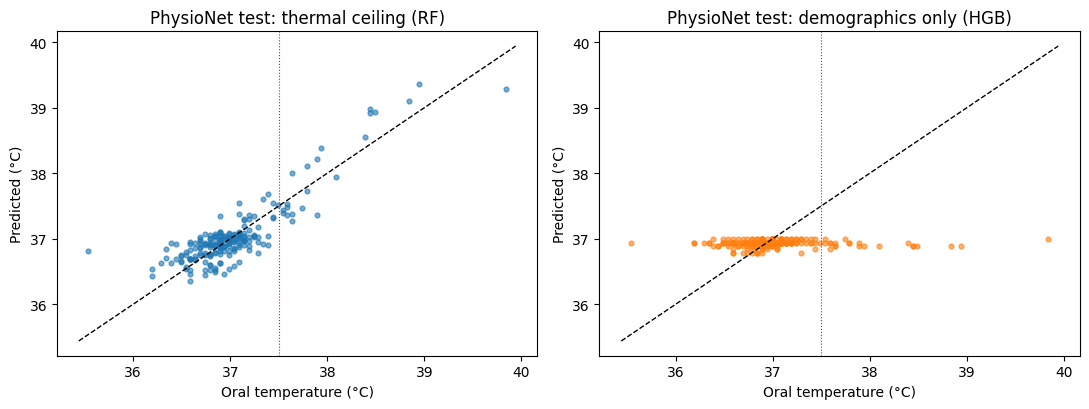

In [ ]:
best_key = min((k for k in phys_preds if k[0] == "thermal ceiling"),
               key=lambda k: np.abs(phys_te["oral_monitor"] - phys_preds[k]).mean())
p = phys_preds[best_key]
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
ax[0].scatter(phys_te["oral_monitor"], p, s=12, alpha=.6)
lims = [phys_te["oral_monitor"].min() - .1, phys_te["oral_monitor"].max() + .1]
ax[0].plot(lims, lims, "k--", lw=1); ax[0].axvline(FEVER_C, color="r", lw=.8, ls=":")
ax[0].set(xlabel="Oral temperature (°C)", ylabel="Predicted (°C)",
          title=f"PhysioNet test: thermal ceiling ({best_key[1]})")
demo_key = min((k for k in phys_preds if k[0] == "B1 demo"),
               key=lambda k: np.abs(phys_te["oral_monitor"] - phys_preds[k]).mean())
ax[1].scatter(phys_te["oral_monitor"], phys_preds[demo_key], s=12, alpha=.6, color="tab:orange")
ax[1].plot(lims, lims, "k--", lw=1); ax[1].axvline(FEVER_C, color="r", lw=.8, ls=":")
ax[1].set(xlabel="Oral temperature (°C)", ylabel="Predicted (°C)",
          title=f"PhysioNet test: demographics only ({demo_key[1]})")
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "w4_fig1_physionet_ceiling.png"), dpi=130); plt.show()

## Phase 3 — Load MCD, harmonise, pooled demographic prior
`db.csv` has one row per patient × step × camera; the labels repeat across cameras, so we keep one row per session (patient, step).

**Patient split.** `train_test_split(patients, test_size=0.2, random_state=43)` with patients in order of first appearance in `db.csv`. If your week-2 notebook built the patient list differently (e.g. sorted), change `PATIENT_ORDER` below. The printed constant MAE should be ≈ 0.093 (week 2) if the split matches.

**Harmonisation.**
- Age: MCD's numeric age is placed into PhysioNet's bins (midpoint), so both datasets use the same `age_mid`.
- `post_exercise`: 1 for MCD "after" sessions; 0 for MCD "before" and for PhysioNet (seated clinic visit, treated as rest).
- Labels are **not** on the same scale (oral vs non-contact forehead device), so raw values are never merged without one of these corrections:

| Strategy | How the label mismatch is handled |
|---|---|
| MCD only | train on MCD only (reference) |
| PhysioNet → MCD offset | train on PhysioNet, shift predictions by the median MCD-train residual |
| Pooled + dataset flag | pool both, add `is_mcd` as a feature (model learns the offset) |
| Pooled, centred | subtract each dataset's train median, pool, add MCD median back |

In [ ]:
PATIENT_ORDER = "appearance"   # "appearance" (pd.unique of db.csv) or "sorted"

db = pd.read_csv(MCD_DB)
need = {"patient_id", "age", "sex", "bmi", "temperature", "pulse", "step", "camera"}
missing = need - set(db.columns)
assert not missing, f"db.csv is missing columns {missing}"

lab_cols = ["temperature", "pulse", "stress", "age", "sex", "bmi"]
nun = db.groupby(["patient_id", "step"])[lab_cols].nunique().max()
if (nun > 1).any():
    print("WARNING: labels differ across camera rows:", nun[nun > 1].to_dict())

sess = (db.drop_duplicates(["patient_id", "step"])
          [["patient_id", "step", "age", "sex", "bmi", "temperature", "pulse",
            "upper_ap", "lower_ap", "saturation", "respiratory", "rigidity", "stress"]]
          .reset_index(drop=True))
sess["sex_male"] = sess["sex"].astype(str).str.upper().str[0].map({"M": 1.0, "F": 0.0})
sess["post_exercise"] = (sess["step"] == "after").astype(float)
sess["age_mid"] = sess["age"].map(age_to_bin_mid)
sess = sess.dropna(subset=["temperature"]).reset_index(drop=True)

patients = pd.unique(db["patient_id"]) if PATIENT_ORDER == "appearance" else np.sort(db["patient_id"].unique())
tr_p, te_p = train_test_split(patients, test_size=0.2, random_state=SEED)
mtr = sess[sess["patient_id"].isin(tr_p)].reset_index(drop=True)
mte = sess[sess["patient_id"].isin(te_p)].reset_index(drop=True)

profile_label(sess["temperature"], "MCD temperature (all sessions)")
wide = sess.pivot_table(index="patient_id", columns="step", values="temperature")
if {"before", "after"} <= set(wide.columns):
    print(f"Patients whose temperature changes before→after: {(wide['before'] != wide['after']).mean()*100:.1f}%")
const_mcd = mtr["temperature"].median()
print(f"\nSplit: {len(tr_p)} train / {len(te_p)} test patients; {len(mtr)} / {len(mte)} sessions")
print(f"MCD constant (train median {const_mcd:.2f}) test MAE = {np.abs(mte['temperature']-const_mcd).mean():.4f}"
      f" | train-mean constant MAE = {np.abs(mte['temperature']-mtr['temperature'].mean()).mean():.4f}"
      "   (week 2: 0.093)")

MCD temperature (all sessions): n=1200 mean=36.563 std=0.133 min=36.00 max=37.50
   quantiles: {0.01: 36.2, 0.05: 36.3, 0.25: 36.5, 0.5: 36.6, 0.75: 36.6, 0.95: 36.7, 0.99: 36.9}
   > 37.5 °C: 0.0%  | >= 37.0 °C: 0.4%
Patients whose temperature changes before→after: 17.3%

Split: 480 train / 120 test patients; 960 / 240 sessions
MCD constant (train median 36.60) test MAE = 0.0929 | train-mean constant MAE = 0.1049   (week 2: 0.093)


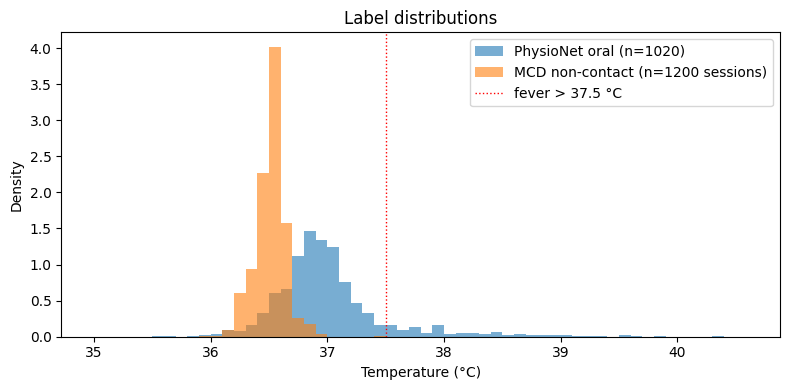

Median offset (PhysioNet oral − MCD): +0.34 °C


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4))
bins = np.arange(35.0, 40.6, 0.1)
ax.hist(phys["oral_monitor"], bins=bins, alpha=.6, density=True, label=f"PhysioNet oral (n={len(phys)})")
ax.hist(sess["temperature"], bins=bins, alpha=.6, density=True, label=f"MCD non-contact (n={len(sess)} sessions)")
ax.axvline(FEVER_C, color="r", ls=":", lw=1, label=f"fever > {FEVER_C} °C")
ax.set(xlabel="Temperature (°C)", ylabel="Density", title="Label distributions")
ax.legend(); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "w4_fig2_label_distributions.png"), dpi=130); plt.show()
print(f"Median offset (PhysioNet oral − MCD): {phys['oral_monitor'].median() - sess['temperature'].median():+.2f} °C")

In [ ]:
SHARED = ["age_mid", "sex_male", "post_exercise"]

# PhysioNet split identical to Phase 2 (same seed, same stratification)
p_tr_idx, p_te_idx = train_test_split(phys.index, test_size=0.2, random_state=SEED, stratify=phys["fever"])
ptr, pte = phys.loc[p_tr_idx].copy(), phys.loc[p_te_idx].copy()
for d in (ptr, pte):
    d["post_exercise"] = 0.0

def frame(d, src):
    y = d["oral_monitor"] if src == "phys" else d["temperature"]
    g = ("P_" + d["subject_id"].astype(str)) if src == "phys" else ("M_" + d["patient_id"].astype(str))
    return pd.DataFrame({**{c: d[c].to_numpy() for c in SHARED},
                         "is_mcd": float(src == "mcd"), "y": y.to_numpy(), "group": g.to_numpy()})

P_tr, P_te, M_tr, M_te = frame(ptr, "phys"), frame(pte, "phys"), frame(mtr, "mcd"), frame(mte, "mcd")
med_p, med_m = P_tr["y"].median(), M_tr["y"].median()

def fit_predict(strategy, model_name, train_P, train_M, targets):
    """Return predictions (°C) for each frame in `targets` = {'mcd': df, 'phys': df}."""
    m = make_models()[model_name]
    out = {}
    if strategy == "MCD only":
        m.fit(train_M[SHARED], train_M["y"])
        out = {k: m.predict(v[SHARED]) for k, v in targets.items() if k == "mcd"}
    elif strategy == "PhysioNet → MCD offset":
        m.fit(train_P[SHARED], train_P["y"])
        off = np.median(train_M["y"] - m.predict(train_M[SHARED]))
        out = {k: m.predict(v[SHARED]) + (off if k == "mcd" else 0.0) for k, v in targets.items()}
    elif strategy == "Pooled + dataset flag":
        X = pd.concat([train_P, train_M]); cols = SHARED + ["is_mcd"]
        m.fit(X[cols], X["y"])
        out = {k: m.predict(v[cols]) for k, v in targets.items()}
    elif strategy == "Pooled, centred":
        mp, mm = train_P["y"].median(), train_M["y"].median()
        X = pd.concat([train_P.assign(y=train_P["y"] - mp), train_M.assign(y=train_M["y"] - mm)])
        m.fit(X[SHARED], X["y"])
        out = {k: m.predict(v[SHARED]) + (mm if k == "mcd" else mp) for k, v in targets.items()}
    return out

STRATEGIES = ["MCD only", "PhysioNet → MCD offset", "Pooled + dataset flag", "Pooled, centred"]
MODELS3 = ["Ridge", "HGB", "RF"]
prior_test_preds = {}
for strat in STRATEGIES:
    for mn in MODELS3:
        pr = fit_predict(strat, mn, P_tr, M_tr, {"mcd": M_te, "phys": P_te})
        prior_test_preds[(strat, mn)] = pr["mcd"]
        evaluate("P3", "MCD test", strat, mn, "age+sex+exercise", M_te["y"], pr["mcd"],
                 np.full(len(M_te), med_m), M_te["group"], fever_thr=FEVER_C)
        if "phys" in pr:
            evaluate("P3", "Phys test", strat, mn, "age+sex+exercise", P_te["y"], pr["phys"],
                     np.full(len(P_te), med_p), P_te["group"], fever_thr=FEVER_C, show=False)

# Week-2 style MCD-only B1 (raw age + sex + BMI + exercise) for reference
B1W2 = ["age", "sex_male", "bmi", "post_exercise"]
for mn in MODELS3:
    m = make_models()[mn].fit(mtr[B1W2], mtr["temperature"])
    evaluate("P3", "MCD test", "MCD only (week-2 B1)", mn, "age+sex+BMI+exercise", mte["temperature"],
             m.predict(mte[B1W2]), np.full(len(mte), med_m), "M_" + mte["patient_id"].astype(str))

[P3] MCD test   MCD only                 Ridge  age+sex+exercise       MAE 0.1047 vs constant 0.0929 -> skill -12.68% [-22.47, -5.26]
[P3] MCD test   MCD only                 HGB    age+sex+exercise       MAE 0.0950 vs constant 0.0929 -> skill  -2.24% [-7.00, +1.40]
[P3] MCD test   MCD only                 RF     age+sex+exercise       MAE 0.1038 vs constant 0.0929 -> skill -11.75% [-21.90, -4.31]
[P3] MCD test   PhysioNet → MCD offset   Ridge  age+sex+exercise       MAE 0.1136 vs constant 0.0929 -> skill -22.27% [-41.62, -9.54]
[P3] MCD test   PhysioNet → MCD offset   HGB    age+sex+exercise       MAE 0.1087 vs constant 0.0929 -> skill -17.04% [-27.05, -9.72]
[P3] MCD test   PhysioNet → MCD offset   RF     age+sex+exercise       MAE 0.1213 vs constant 0.0929 -> skill -30.56% [-54.42, -13.91]
[P3] MCD test   Pooled + dataset flag    Ridge  age+sex+exercise       MAE 0.1035 vs constant 0.0929 -> skill -11.41% [-22.60, -3.04]
[P3] MCD test   Pooled + dataset flag    HGB    age+sex+exerci

In [ ]:
print("PhysioNet-test results for the strategies that use PhysioNet (skill vs PhysioNet constant):")
display(pd.DataFrame([r for r in RESULTS if r["phase"] == "P3" and r["eval_set"] == "Phys test"])
        [["strategy", "model", "MAE", "ref_MAE", "skill_pct", "skill_lo", "skill_hi", "fever_AUC"]])

PhysioNet-test results for the strategies that use PhysioNet (skill vs PhysioNet constant):


,strategy,model,MAE,ref_MAE,skill_pct,skill_lo,skill_hi,fever_AUC
0,PhysioNet → MCD offset,Ridge,0.3229,0.3071,-5.16,-10.14,-0.82,0.686
1,PhysioNet → MCD offset,HGB,0.3020,0.3071,1.68,-0.33,3.87,0.377
2,PhysioNet → MCD offset,RF,0.3221,0.3071,-4.89,-10.64,-0.02,0.645
3,Pooled + dataset flag,Ridge,0.3199,0.3071,-4.15,-8.60,-0.23,0.684
4,Pooled + dataset flag,HGB,0.3010,0.3071,2.00,0.09,4.09,0.360
5,Pooled + dataset flag,RF,0.3221,0.3071,-4.87,-10.58,-0.01,0.707
6,"Pooled, centred",Ridge,0.3136,0.3071,-2.11,-4.44,-0.05,0.684
7,"Pooled, centred",HGB,0.3040,0.3071,1.00,-0.30,2.44,0.529
8,"Pooled, centred",RF,0.3130,0.3071,-1.93,-5.22,0.98,0.705


## Phase 4 — rPPG / heart-rate residual on top of the prior (MCD only)
The prior is chosen **on MCD-train only** (grouped 5-fold out-of-fold MAE), never on test. The residual model then learns `temperature − prior` from HR/rPPG features.

- If `RPPG_FEATURES_CSV` is set, its numeric columns (merged on `patient_id`, `step`) are the rPPG features.
- Otherwise the spot `pulse` reading is used as an **oracle HR proxy**. Week 2 measured FullHD rPPG HR within 0.66 BPM of contact PPG, so this approximates what perfect rPPG HR would give. It is a diagnostic, not a deployable result.

Physiological rationale: fever raises HR by roughly 8–10 BPM per °C, so HR is the main route by which rPPG could see temperature.

In [ ]:
def oof_prior(strategy, model_name, n_splits=5):
    """Out-of-fold prior predictions on MCD train (folds by patient)."""
    oof = np.zeros(len(M_tr))
    for a, b in GroupKFold(n_splits=n_splits).split(M_tr, groups=M_tr["group"]):
        oof[b] = fit_predict(strategy, model_name, P_tr, M_tr.iloc[a], {"mcd": M_tr.iloc[b]})["mcd"]
    return oof

cands = {}
for strat in STRATEGIES:
    for mn in ["Ridge", "HGB"]:
        o = oof_prior(strat, mn)
        cands[(strat, mn)] = (np.abs(M_tr["y"] - o).mean(), o)
        print(f"OOF prior {strat:<24} {mn:<6} MAE {cands[(strat, mn)][0]:.4f}")
const_oof = np.abs(M_tr["y"] - M_tr["y"].median()).mean()
print(f"OOF constant MAE {const_oof:.4f}")
PRIOR = min(cands, key=lambda k: cands[k][0])
prior_oof = cands[PRIOR][1]
prior_te = prior_test_preds[PRIOR]
print("\nChosen prior (train CV only):", PRIOR)

OOF prior MCD only                 Ridge  MAE 0.1001
OOF prior MCD only                 HGB    MAE 0.0957
OOF prior PhysioNet → MCD offset   Ridge  MAE 0.1151
OOF prior PhysioNet → MCD offset   HGB    MAE 0.1053
OOF prior Pooled + dataset flag    Ridge  MAE 0.1012
OOF prior Pooled + dataset flag    HGB    MAE 0.0957
OOF prior Pooled, centred          Ridge  MAE 0.1136
OOF prior Pooled, centred          HGB    MAE 0.0947
OOF constant MAE 0.0930

Chosen prior (train CV only): ('Pooled, centred', 'HGB')


In [ ]:
# ---- rPPG / HR features ----
if RPPG_FEATURES_CSV and os.path.exists(RPPG_FEATURES_CSV):
    rf = pd.read_csv(RPPG_FEATURES_CSV)
    assert {"patient_id", "step"} <= set(rf.columns), "feature table needs patient_id and step columns"
    if "camera" in rf.columns:
        rf = rf[rf["camera"] == CAMERA]
    rf = rf.drop_duplicates(["patient_id", "step"])
    feat_cols = [c for c in rf.select_dtypes("number").columns if c not in ("patient_id",)]
    FEAT_LABEL = f"rPPG features ({len(feat_cols)})"
    mtr4 = mtr.merge(rf[["patient_id", "step"] + feat_cols], on=["patient_id", "step"], how="left")
    mte4 = mte.merge(rf[["patient_id", "step"] + feat_cols], on=["patient_id", "step"], how="left")
    print(f"Loaded {len(feat_cols)} rPPG features; coverage train "
          f"{mtr4[feat_cols].notna().any(axis=1).mean()*100:.0f}% / test {mte4[feat_cols].notna().any(axis=1).mean()*100:.0f}%")
else:
    if RPPG_FEATURES_CSV:
        print("RPPG_FEATURES_CSV not found:", RPPG_FEATURES_CSV)
    print("Using spot pulse as ORACLE HR proxy (diagnostic only).")
    hits = glob.glob(os.path.join(MCD_ROOT, "**", "*feat*.csv"), recursive=True)[:10]
    if hits:
        print("Candidate week-2 feature tables found on Drive (set RPPG_FEATURES_CSV to one of these):")
        for h in hits: print("   ", h)
    mtr4, mte4 = mtr.copy(), mte.copy()
    for d in (mtr4, mte4):
        d["hr"] = d["pulse"]
        d["hr_x_exercise"] = d["pulse"] * d["post_exercise"]
    feat_cols = ["hr", "hr_x_exercise"]
    FEAT_LABEL = "HR proxy (oracle)"

X4_cols = feat_cols + ["post_exercise"]
res_tr = M_tr["y"].to_numpy() - prior_oof
for mn in ["Ridge", "HGB"]:
    m = make_models()[mn].fit(mtr4[X4_cols], res_tr)
    pred = prior_te + m.predict(mte4[X4_cols])
    # vs the prior alone (does HR/rPPG add anything?) and vs the constant
    evaluate("P4", "MCD test", f"prior + residual", mn, FEAT_LABEL, mte["temperature"], pred,
             prior_te, M_te["group"], ref_name="prior")
    evaluate("P4", "MCD test", f"prior + residual", mn, FEAT_LABEL, mte["temperature"], pred,
             np.full(len(mte), med_m), M_te["group"], ref_name="constant")
    # direct model (no prior): temperature ~ features + demographics, MCD only
    cols_d = X4_cols + ["age", "sex_male", "bmi"]
    md_ = make_models()[mn].fit(mtr4[cols_d], mtr["temperature"])
    evaluate("P4", "MCD test", "MCD only, direct", mn, FEAT_LABEL + "+demo", mte["temperature"],
             md_.predict(mte4[cols_d]), np.full(len(mte), med_m), M_te["group"])

Using spot pulse as ORACLE HR proxy (diagnostic only).
Candidate week-2 feature tables found on Drive (set RPPG_FEATURES_CSV to one of these):
    /content/drive/MyDrive/MCD_rPPG/results/week2_baselines/features_rppg.csv
    /content/drive/MyDrive/MCD_rPPG/results/week2_baselines/features_cppg.csv
    /content/drive/MyDrive/MCD_rPPG/results/week2_baselines/features_grid.csv
    /content/drive/MyDrive/MCD_rPPG/results/week2_baselines/features_hrv_ecg_ppg.csv
    /content/drive/MyDrive/MCD_rPPG/week3_stress_rppg600/features/session_features.csv
    /content/drive/MyDrive/MCD_rPPG/week3_stress_rppg600/features/patient_features.csv
[P4] MCD test   prior + residual         Ridge  HR proxy (oracle)      MAE 0.1040 vs prior 0.0949 -> skill  -9.57% [-16.94, -3.93]
[P4] MCD test   prior + residual         Ridge  HR proxy (oracle)      MAE 0.1040 vs constant 0.0929 -> skill -11.88% [-21.47, -4.65]
[P4] MCD test   MCD only, direct         Ridge  HR proxy (oracle)+demo MAE 0.1048 vs constant 0.092

## Phase 5 — Physiology check: how much temperature signal can HR carry in MCD?
If temperature drove HR at ~8–10 BPM/°C, MCD's temperature spread (std ≈ 0.13 °C) would move HR by only ~1 BPM, while HR varies between people by ~10+ BPM and squats move it by ~20 BPM. This cell quantifies that ratio and tests the within-person relation (Δtemperature vs ΔHR, before → after).

MCD rest sessions: temperature sd 0.133 °C, HR sd 13.0 BPM
Expected HR sd caused by temperature: 1.20 BPM = 0.8% of HR variance (upper bound on what HR can explain)
Rest: Spearman(temp, HR) = -0.005 (p=0.902)
Within person: ΔHR mean +19.5 BPM, ΔT mean +0.012 °C, Spearman(ΔT, ΔHR) = -0.023 (p=0.579), 104 patients with ΔT ≠ 0


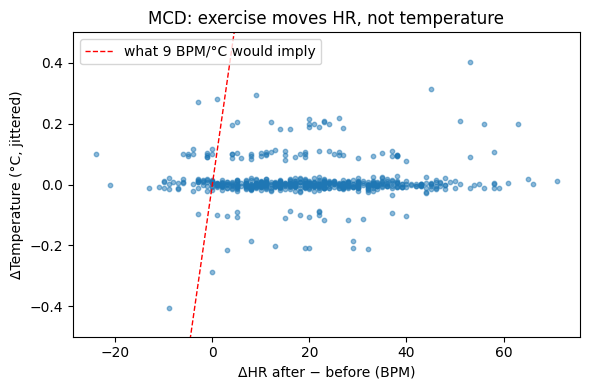

In [ ]:
SLOPE = 9.0   # BPM per °C, midpoint of the 8-10 BPM/°C rule of thumb
before = sess[sess["step"] == "before"]
t_sd, hr_sd = before["temperature"].std(), before["pulse"].std()
print(f"MCD rest sessions: temperature sd {t_sd:.3f} °C, HR sd {hr_sd:.1f} BPM")
print(f"Expected HR sd caused by temperature: {SLOPE*t_sd:.2f} BPM "
      f"= {100*(SLOPE*t_sd)**2/hr_sd**2:.1f}% of HR variance (upper bound on what HR can explain)")
r, p = stats.spearmanr(before["temperature"], before["pulse"])
print(f"Rest: Spearman(temp, HR) = {r:+.3f} (p={p:.3g})")

w = sess.pivot_table(index="patient_id", columns="step", values=["temperature", "pulse"])
if ("temperature", "after") in w.columns:
    dT = w[("temperature", "after")] - w[("temperature", "before")]
    dH = w[("pulse", "after")] - w[("pulse", "before")]
    ok = dT.notna() & dH.notna()
    r2, p2 = stats.spearmanr(dT[ok], dH[ok])
    print(f"Within person: ΔHR mean {dH[ok].mean():+.1f} BPM, ΔT mean {dT[ok].mean():+.3f} °C, "
          f"Spearman(ΔT, ΔHR) = {r2:+.3f} (p={p2:.3g}), {int((dT[ok]!=0).sum())} patients with ΔT ≠ 0")
    fig, ax = plt.subplots(figsize=(6, 4))
    ax.scatter(dH[ok], dT[ok] + np.random.default_rng(SEED).normal(0, .01, ok.sum()), s=10, alpha=.5)
    xs = np.linspace(dH[ok].min(), dH[ok].max(), 10)
    ax.plot(xs, xs / SLOPE, "r--", lw=1, label=f"what {SLOPE:.0f} BPM/°C would imply")
    ax.set(xlabel="ΔHR after − before (BPM)", ylabel="ΔTemperature (°C, jittered)",
           title="MCD: exercise moves HR, not temperature", ylim=(-0.5, 0.5)); ax.legend(loc="upper left")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "w4_fig3_dHR_dT.png"), dpi=130); plt.show()

## Phase 6 — Results table and decision gate

In [ ]:
res = pd.DataFrame(RESULTS)
res.to_csv(os.path.join(OUT_DIR, "w4_results.csv"), index=False)
cols = ["phase", "eval_set", "strategy", "model", "features", "n", "MAE", "ref", "ref_MAE",
        "skill_pct", "skill_lo", "skill_hi", "fever_AUC"]
for ph in ["P2", "P3", "P4"]:
    print(f"\n==== {ph} ====")
    display(res[res["phase"] == ph][cols].reset_index(drop=True))
print("\nSaved:", os.path.join(OUT_DIR, "w4_results.csv"))


==== P2 ====


,phase,eval_set,strategy,model,features,n,MAE,ref,ref_MAE,skill_pct,skill_lo,skill_hi,fever_AUC
0,P2,Phys-FLIR,PhysioNet only,Ridge,B1 demo,204,0.3229,constant,0.3071,-5.16,-10.14,-0.82,0.686
1,P2,Phys-FLIR,PhysioNet only,RF,B1 demo,204,0.3221,constant,0.3071,-4.89,-10.64,-0.02,0.645
2,P2,Phys-FLIR,PhysioNet only,HGB,B1 demo,204,0.3020,constant,0.3071,1.68,-0.33,3.87,0.377
3,P2,Phys-FLIR,PhysioNet only,Ridge,B1+env,204,0.3254,constant,0.3071,-5.97,-12.63,-0.65,0.681
4,P2,Phys-FLIR,PhysioNet only,RF,B1+env,204,0.3465,constant,0.3071,-12.81,-22.90,-4.54,0.534
5,P2,Phys-FLIR,PhysioNet only,HGB,B1+env,204,0.3269,constant,0.3071,-6.45,-12.69,-0.88,0.522
6,P2,Phys-FLIR,PhysioNet only,Ridge,thermal ceiling,204,0.2088,constant,0.3071,32.02,18.97,42.92,0.979
7,P2,Phys-FLIR,PhysioNet only,RF,thermal ceiling,204,0.1844,constant,0.3071,39.95,30.02,48.22,0.986
8,P2,Phys-FLIR,PhysioNet only,HGB,thermal ceiling,204,0.1854,constant,0.3071,39.64,29.36,48.69,0.976
9,P2,Phys-ICI,PhysioNet only,Ridge,B1 demo,202,0.3013,constant,0.3030,0.54,-3.99,4.64,0.623



==== P3 ====


,phase,eval_set,strategy,model,features,n,MAE,ref,ref_MAE,skill_pct,skill_lo,skill_hi,fever_AUC
0,P3,MCD test,MCD only,Ridge,age+sex+exercise,240,0.1047,constant,0.0929,-12.68,-22.47,-5.26,NaN
1,P3,MCD test,MCD only,HGB,age+sex+exercise,240,0.0950,constant,0.0929,-2.24,-7.00,1.40,NaN
2,P3,MCD test,MCD only,RF,age+sex+exercise,240,0.1038,constant,0.0929,-11.75,-21.90,-4.31,NaN
3,P3,MCD test,PhysioNet → MCD offset,Ridge,age+sex+exercise,240,0.1136,constant,0.0929,-22.27,-41.62,-9.54,NaN
4,P3,Phys test,PhysioNet → MCD offset,Ridge,age+sex+exercise,204,0.3229,constant,0.3071,-5.16,-10.14,-0.82,0.686
5,P3,MCD test,PhysioNet → MCD offset,HGB,age+sex+exercise,240,0.1087,constant,0.0929,-17.04,-27.05,-9.72,NaN
6,P3,Phys test,PhysioNet → MCD offset,HGB,age+sex+exercise,204,0.3020,constant,0.3071,1.68,-0.33,3.87,0.377
7,P3,MCD test,PhysioNet → MCD offset,RF,age+sex+exercise,240,0.1213,constant,0.0929,-30.56,-54.42,-13.91,NaN
8,P3,Phys test,PhysioNet → MCD offset,RF,age+sex+exercise,204,0.3221,constant,0.3071,-4.89,-10.64,-0.02,0.645
9,P3,MCD test,Pooled + dataset flag,Ridge,age+sex+exercise,240,0.1035,constant,0.0929,-11.41,-22.60,-3.04,NaN



==== P4 ====


,phase,eval_set,strategy,model,features,n,MAE,ref,ref_MAE,skill_pct,skill_lo,skill_hi,fever_AUC
0,P4,MCD test,prior + residual,Ridge,HR proxy (oracle),240,0.1040,prior,0.0949,-9.57,-16.94,-3.93,NaN
1,P4,MCD test,prior + residual,Ridge,HR proxy (oracle),240,0.1040,constant,0.0929,-11.88,-21.47,-4.65,NaN
2,P4,MCD test,"MCD only, direct",Ridge,HR proxy (oracle)+demo,240,0.1048,constant,0.0929,-12.79,-22.62,-5.36,NaN
3,P4,MCD test,prior + residual,HGB,HR proxy (oracle),240,0.1003,prior,0.0949,-5.71,-13.60,1.32,NaN
4,P4,MCD test,prior + residual,HGB,HR proxy (oracle),240,0.1003,constant,0.0929,-7.94,-17.63,0.05,NaN
5,P4,MCD test,"MCD only, direct",HGB,HR proxy (oracle)+demo,240,0.0975,constant,0.0929,-4.93,-16.45,4.66,NaN



Saved: /content/drive/MyDrive/MCD_rPPG/week4_outputs/w4_results.csv


In [ ]:
def best(df):
    return df.loc[df["MAE"].idxmin()] if len(df) else None

summary = []
b = best(res[(res.phase == "P2") & (res.eval_set == "Phys-FLIR") & (res.features == "thermal ceiling")])
d = best(res[(res.phase == "P2") & (res.eval_set == "Phys-FLIR") & (res.features == "B1 demo")])
if b is not None:
    summary.append(f"PhysioNet thermal ceiling ({b.model}): MAE {b.MAE:.3f} °C vs constant {b.ref_MAE:.3f} "
                   f"(skill {b.skill_pct:+.1f}% [{b.skill_lo:+.1f}, {b.skill_hi:+.1f}]), fever AUC {b.fever_AUC}.")
if d is not None:
    summary.append(f"PhysioNet demographics only ({d.model}): skill {d.skill_pct:+.1f}% "
                   f"[{d.skill_lo:+.1f}, {d.skill_hi:+.1f}], fever AUC {d.fever_AUC}.")
mc = res[(res.phase == "P3") & (res.eval_set == "MCD test")]
bm = best(mc)
if bm is not None:
    summary.append(f"Best MCD prior on test: {bm.strategy} / {bm.model}: MAE {bm.MAE:.4f} vs constant "
                   f"{bm.ref_MAE:.4f} (skill {bm.skill_pct:+.1f}% [{bm.skill_lo:+.1f}, {bm.skill_hi:+.1f}]).")
p4 = res[(res.phase == "P4") & (res.ref == "prior")]
b4 = best(p4)
if b4 is not None:
    summary.append(f"Adding {b4.features} to the prior ({b4.model}): skill vs prior {b4.skill_pct:+.1f}% "
                   f"[{b4.skill_lo:+.1f}, {b4.skill_hi:+.1f}].")
summary.append(f"Chosen prior (train CV): {PRIOR[0]} / {PRIOR[1]}.")
print("\n".join("• " + s for s in summary))
with open(os.path.join(OUT_DIR, "w4_summary.txt"), "w") as f:
    f.write("\n".join(summary))

• PhysioNet thermal ceiling (RF): MAE 0.184 °C vs constant 0.307 (skill +40.0% [+30.0, +48.2]), fever AUC 0.986.
• PhysioNet demographics only (HGB): skill +1.7% [-0.3, +3.9], fever AUC 0.377.
• Best MCD prior on test: Pooled + dataset flag / HGB: MAE 0.0938 vs constant 0.0929 (skill -0.9% [-3.2, -0.0]).
• Adding HR proxy (oracle) to the prior (HGB): skill vs prior -5.7% [-13.6, +1.3].
• Chosen prior (train CV): Pooled, centred / HGB.


### How to read the results (for the weekly report)
- **An interval that includes 0 % means no detectable gain over the reference.** Report the constant baseline next to every number.
- **Phase 2** sets the ceiling: if facial thermal features reach high fever AUC on PhysioNet, temperature is visible to a camera that measures heat. Demographics alone should be near chance.
- **Phase 3** tests whether pooling PhysioNet helps MCD. Expected: no strategy beats the MCD constant (≈ 0.093), because MCD's labels have almost no variance to explain. If pooled strategies keep PhysioNet-test skill while matching the MCD constant, the pooled prior is still useful as a fever-aware starting point.
- **Phase 4** isolates the rPPG/HR contribution. The oracle-HR version is an upper bound for rPPG HR.
- **Phase 5** explains a null result physically: in afebrile data, temperature can account for only a tiny share of HR variance, while exercise dominates ΔHR.

### Decision gate
1. If Phase 4 skill vs prior is ≤ 0 (interval includes 0) even with oracle HR, **rPPG → temperature cannot be learned from MCD**, and PhysioNet cannot fix that because it has no video.
2. Next options, in order:
   - **LVT** (EURECOM; paired RGB + thermal video, 52 subjects, infrared-thermometer labels; licence by email): check its temperature range, then extract POS rPPG and run the Phase 3 prior + Phase 4 residual unchanged as an external test.
   - **Collect** paired face video + reference temperature with febrile patients.
   - **Pivot to thermal input**, where PhysioNet is strong (Phase 2 ceiling).